
# Historical Backtesting — Germany Renewable Generation Forecast

## 1. Project Overview

This notebook evaluates the performance of trained machine learning models for forecasting renewable electricity generation in Germany.

The evaluation covers three generation technologies:

- Solar photovoltaic (PV)
- Onshore wind
- Offshore wind

## 2. Backtesting Objectives

- Evaluate saved models using historical weather data.
- Compare predicted generation against actual German generation data.
- Measure forecasting performance using MAE, RMSE, WAPE and Bias.
- Analyse hourly and daily forecasting errors.
- Identify differences in model performance across technologies.

## 3. Data Sources

- Historical weather data: Open-Meteo
- Actual electricity generation: SMARD
- Trained models: Saved project model files

## 4. Evaluation Period

June 2024

## 5. Important Methodological Note

This experiment uses archived historical weather data. It is a historical model-performance evaluation and does not represent a fully operational day-ahead backtest using weather forecasts available before the market gate closure.


In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

# Project directories
root = Path(r"D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast")
base = root.parent

# Model files
model_files = [
    root / "models" / "Solar" / "solar_model.pkl",
    root / "models" / "Wind" / "final_wind_models.pkl",
    root / "models" / "Wind" / "final_wind_calibrators.pkl",
    root / "models" / "Shared" / "feature_columns.pkl"
]

# Historical data files
generation_file = base / "germany_historical_generation.csv"

weather_files = [
    base / "germany_archived_weather_17_locations_experimental.csv",
    base / "germany_archived_weather_22_locations_offshore_experimental.csv"
]

print("PROJECT DIRECTORY:", root.exists())
print("\nMODEL FILES")

for file in model_files:
    print(file.name, "—", file.exists())

print("\nGENERATION DATA")
print(generation_file.name, "—", generation_file.exists())

print("\nWEATHER DATA")

for file in weather_files:
    print(file.name, "—", file.exists())


PROJECT DIRECTORY: True

MODEL FILES
solar_model.pkl — True
final_wind_models.pkl — True
final_wind_calibrators.pkl — True
feature_columns.pkl — True

GENERATION DATA
germany_historical_generation.csv — True

WEATHER DATA
germany_archived_weather_17_locations_experimental.csv — False
germany_archived_weather_22_locations_offshore_experimental.csv — False


In [2]:
weather_folder = base / "germany_weather_data"

print("WEATHER FOLDER EXISTS:", weather_folder.exists())

if weather_folder.exists():
    print("\nFILES INSIDE WEATHER FOLDER:")
    for file in weather_folder.glob("*.csv"):
        print(file.name)

WEATHER FOLDER EXISTS: True

FILES INSIDE WEATHER FOLDER:
generation_hourly_profile.csv
germany_archived_weather_17_locations_experimental.csv
germany_archived_weather_22_locations_offshore_experimental.csv
germany_archived_weather_4_new_locations.csv
germany_archived_weather_4_new_locations_checkpoint.csv
germany_archived_weather_5_new_offshore_locations.csv
germany_archived_weather_5_new_offshore_locations_checkpoint.csv
germany_archived_weather_batch_01.csv
germany_archived_weather_batch_02.csv
germany_archived_weather_batch_03.csv
germany_archived_weather_batch_04.csv
germany_archived_weather_batch_05.csv
germany_archived_weather_batch_06.csv
germany_archived_weather_batch_07.csv
germany_archived_weather_batch_08.csv
germany_archived_weather_batch_09.csv
germany_archived_weather_batch_10.csv
germany_archived_weather_batch_11.csv
germany_archived_weather_batch_12.csv
germany_archived_weather_batch_13.csv
germany_archived_weather_batch_14.csv
germany_archived_weather_batch_15.csv
ger

In [3]:
weather_folder = base / "germany_weather_data"

weather_files = [
    weather_folder / "germany_archived_weather_17_locations_experimental.csv",
    weather_folder / "germany_archived_weather_22_locations_offshore_experimental.csv"
]

print("WEATHER FILE CHECK")

for file in weather_files:
    print(file.name, "—", file.exists())

WEATHER FILE CHECK
germany_archived_weather_17_locations_experimental.csv — True
germany_archived_weather_22_locations_offshore_experimental.csv — True


In [4]:
# Load historical generation data
generation = pd.read_csv(generation_file)

# Load archived weather datasets
weather17 = pd.read_csv(weather_files[0])
weather22 = pd.read_csv(weather_files[1])

print("=" * 60)
print("DATASET LOADING SUMMARY")
print("=" * 60)

print("\nGENERATION DATA")
print("Shape:", generation.shape)
print("Columns:", generation.columns.tolist())

print("\n17-LOCATION WEATHER")
print("Shape:", weather17.shape)
print("Columns:", weather17.columns.tolist())

print("\n22-LOCATION WEATHER")
print("Shape:", weather22.shape)
print("Columns:", weather22.columns.tolist())

print("\nGENERATION SAMPLE")
display(generation.head(3))

print("\n17-LOCATION WEATHER SAMPLE")
display(weather17.head(3))

print("\n22-LOCATION WEATHER SAMPLE")
display(weather22.head(3))

DATASET LOADING SUMMARY

GENERATION DATA
Shape: (34728, 4)
Columns: ['time', 'onshore_wind_mw', 'offshore_wind_mw', 'solar_mw']

17-LOCATION WEATHER
Shape: (398208, 14)
Columns: ['time', 'wind_speed_100m', 'wind_direction_100m', 'temperature_2m', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'cloud_cover', 'location', 'latitude', 'longitude', 'region', 'type', 'run_time_utc']

22-LOCATION WEATHER
Shape: (515328, 18)
Columns: ['time', 'wind_speed_100m', 'wind_direction_100m', 'wind_direction_sin', 'wind_direction_cos', 'temperature_2m', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'cloud_cover', 'location', 'latitude', 'longitude', 'region', 'type', 'run_time_utc', 'time_utc', 'time_local']

GENERATION SAMPLE


,time,onshore_wind_mw,offshore_wind_mw,solar_mw
0,2022-12-01 00:00:00+01:00,2707.50,1060.50,4.00
1,2022-12-01 01:00:00+01:00,2476.00,1283.75,3.50
2,2022-12-01 02:00:00+01:00,2304.25,1382.25,3.25



17-LOCATION WEATHER SAMPLE


,time,wind_speed_100m,wind_direction_100m,temperature_2m,shortwave_radiation,direct_radiation,diffuse_radiation,cloud_cover,location,latitude,longitude,region,type,run_time_utc
0,2024-03-15 00:00:00+01:00,9.64,198.0,7.9,0.0,0.0,0.0,98.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00
1,2024-03-15 01:00:00+01:00,9.60,198.0,7.7,0.0,0.0,0.0,99.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00
2,2024-03-15 02:00:00+01:00,9.48,196.0,7.5,0.0,0.0,0.0,100.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00



22-LOCATION WEATHER SAMPLE


,time,wind_speed_100m,wind_direction_100m,wind_direction_sin,wind_direction_cos,temperature_2m,shortwave_radiation,direct_radiation,diffuse_radiation,cloud_cover,location,latitude,longitude,region,type,run_time_utc,time_utc,time_local
0,2024-03-15 00:00:00+01:00,9.64,198.0,-0.309017,-0.951057,7.9,0.0,0.0,0.0,98.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-14 23:00:00+00:00,2024-03-15 00:00:00+01:00
1,2024-03-15 01:00:00+01:00,9.60,198.0,-0.309017,-0.951057,7.7,0.0,0.0,0.0,99.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 00:00:00+00:00,2024-03-15 01:00:00+01:00
2,2024-03-15 02:00:00+01:00,9.48,196.0,-0.275637,-0.961262,7.5,0.0,0.0,0.0,100.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 01:00:00+00:00,2024-03-15 02:00:00+01:00


In [5]:
# Standardise timestamps to UTC for comparison

generation["time"] = pd.to_datetime(generation["time"], utc=True)
weather17["time"] = pd.to_datetime(weather17["time"], utc=True)
weather22["time"] = pd.to_datetime(weather22["time"], utc=True)

print("=" * 60)
print("HISTORICAL DATA COVERAGE")
print("=" * 60)

for name, df in [
    ("Generation", generation),
    ("Weather 17 locations", weather17),
    ("Weather 22 locations", weather22)
]:
    print(f"\n{name}")
    print("First timestamp:", df["time"].min())
    print("Last timestamp:", df["time"].max())
    print("Unique timestamps:", df["time"].nunique())

print("\nJUNE 2024 GENERATION")
june_generation = generation[
    generation["time"].dt.strftime("%Y-%m") == "2024-06"
]
print("Rows:", len(june_generation))

print("\nJUNE 2024 WEATHER")
for name, df in [
    ("17 locations", weather17),
    ("22 locations", weather22)
]:
    june = df[df["time"].dt.strftime("%Y-%m") == "2024-06"]
    print(name, "—", len(june), "rows")

HISTORICAL DATA COVERAGE

Generation
First timestamp: 2022-11-30 23:00:00+00:00
Last timestamp: 2026-11-16 22:00:00+00:00
Unique timestamps: 34728

Weather 17 locations
First timestamp: 2024-03-14 23:00:00+00:00
Last timestamp: 2026-11-16 22:00:00+00:00
Unique timestamps: 23424

Weather 22 locations
First timestamp: 2024-03-14 23:00:00+00:00
Last timestamp: 2026-11-16 22:00:00+00:00
Unique timestamps: 23424

JUNE 2024 GENERATION
Rows: 720

JUNE 2024 WEATHER
17 locations — 12240 rows
22 locations — 15840 rows


In [7]:

import joblib

# Load saved models and feature configuration

solar_model = joblib.load(
    root / "models" / "Solar" / "solar_model.pkl"
)

wind_models = joblib.load(
    root / "models" / "Wind" / "final_wind_models.pkl"
)

wind_calibrators = joblib.load(
    root / "models" / "Wind" / "final_wind_calibrators.pkl"
)

feature_columns = joblib.load(
    root / "models" / "Shared" / "feature_columns.pkl"
)

print("=" * 60)
print("SAVED MODEL LOADING SUMMARY")
print("=" * 60)

print("\nSOLAR MODEL:", type(solar_model).__name__)

print("\nWIND MODELS:", list(wind_models.keys()))

print("\nWIND CALIBRATORS:", list(wind_calibrators.keys()))

print("\nFEATURE CONFIGURATION:", type(feature_columns).__name__)


SAVED MODEL LOADING SUMMARY

SOLAR MODEL: HistGradientBoostingRegressor

WIND MODELS: ['offshore', 'onshore']

WIND CALIBRATORS: ['offshore', 'onshore']

FEATURE CONFIGURATION: list


In [8]:

# Inspect the saved feature configuration

print("=" * 60)
print("MODEL FEATURE CONFIGURATION")
print("=" * 60)

print("\nSOLAR FEATURES")
print("Count:", len(feature_columns))
print("First 15 features:")
for feature in feature_columns[:15]:
    print(" -", feature)

print("\nONSHORE FEATURES")
onshore_features = list(wind_models["onshore"].booster_.feature_name())
print("Count:", len(onshore_features))
print("First 15 features:")
for feature in onshore_features[:15]:
    print(" -", feature)

print("\nOFFSHORE FEATURES")
offshore_features = list(wind_models["offshore"].booster_.feature_name())
print("Count:", len(offshore_features))
print("First 15 features:")
for feature in offshore_features[:15]:
    print(" -", feature)


MODEL FEATURE CONFIGURATION

SOLAR FEATURES
Count: 108
First 15 features:
 - wind_speed_100m_Baltic_Sea_1
 - wind_speed_100m_Baltic_Sea_2
 - wind_speed_100m_Berlin
 - wind_speed_100m_Braunschweig
 - wind_speed_100m_Bremen
 - wind_speed_100m_Dresden
 - wind_speed_100m_Dusseldorf
 - wind_speed_100m_Frankfurt
 - wind_speed_100m_Hamburg
 - wind_speed_100m_Munich
 - wind_speed_100m_North_Sea_1
 - wind_speed_100m_North_Sea_2
 - wind_speed_100m_North_Sea_3
 - wind_direction_sin_Baltic_Sea_1
 - wind_direction_sin_Baltic_Sea_2

ONSHORE FEATURES
Count: 140
First 15 features:
 - wind_speed_100m_Baltic_Sea_1
 - wind_speed_100m_Baltic_Sea_2
 - wind_speed_100m_Berlin
 - wind_speed_100m_Braunschweig
 - wind_speed_100m_Bremen
 - wind_speed_100m_Dresden
 - wind_speed_100m_Dusseldorf
 - wind_speed_100m_Frankfurt
 - wind_speed_100m_Hamburg
 - wind_speed_100m_Munich
 - wind_speed_100m_North_Sea_1
 - wind_speed_100m_North_Sea_2
 - wind_speed_100m_North_Sea_3
 - wind_direction_sin_Baltic_Sea_1
 - wind_direc

In [9]:

print("=" * 60)
print("FINAL FEATURES — SOLAR")
print("=" * 60)
print("\n".join(feature_columns[-20:]))

print("\n" + "=" * 60)
print("FINAL FEATURES — ONSHORE")
print("=" * 60)
print("\n".join(onshore_features[-25:]))

print("\n" + "=" * 60)
print("FINAL FEATURES — OFFSHORE")
print("=" * 60)
print("\n".join(offshore_features[-25:]))

print("\n" + "=" * 60)
print("WEATHER LOCATIONS")
print("=" * 60)
print(sorted(weather22["location"].unique()))


FINAL FEATURES — SOLAR
diffuse_radiation_North_Sea_1
diffuse_radiation_North_Sea_2
diffuse_radiation_North_Sea_3
cloud_cover_Baltic_Sea_1
cloud_cover_Baltic_Sea_2
cloud_cover_Berlin
cloud_cover_Braunschweig
cloud_cover_Bremen
cloud_cover_Dresden
cloud_cover_Dusseldorf
cloud_cover_Frankfurt
cloud_cover_Hamburg
cloud_cover_Munich
cloud_cover_North_Sea_1
cloud_cover_North_Sea_2
cloud_cover_North_Sea_3
hour_sin
hour_cos
day_of_year_sin
day_of_year_cos

FINAL FEATURES — ONSHORE
diffuse_radiation_Schleswig_Holstein
direct_radiation_Brandenburg
direct_radiation_Niedersachsen
direct_radiation_Nordrhein_Westfalen
direct_radiation_Schleswig_Holstein
shortwave_radiation_Brandenburg
shortwave_radiation_Niedersachsen
shortwave_radiation_Nordrhein_Westfalen
shortwave_radiation_Schleswig_Holstein
temperature_2m_Brandenburg
temperature_2m_Niedersachsen
temperature_2m_Nordrhein_Westfalen
temperature_2m_Schleswig_Holstein
wind_direction_cos_Brandenburg
wind_direction_cos_Niedersachsen
wind_direction_cos

In [10]:
# Inspect existing feature-engineering functions

feature_source_files = [
    root / "src" / "features" / "weather_features.py",
    root / "src" / "features" / "weather_aggregation.py",
    root / "src" / "features" / "weather_transformations.py"
]

for file in feature_source_files:
    print("\n" + "=" * 70)
    print(file.name)
    print("=" * 70)

    if file.exists():
        source = file.read_text(encoding="utf-8")
        print(source)
    else:
        print("FILE NOT FOUND")


weather_features.py

import numpy as np
import pandas as pd


def add_cyclical_time_features(df):
    """
    Add cyclical hour-of-day and day-of-year features.

    Cyclical encoding represents time as a continuous cycle,
    so that adjacent periods remain close to each other.
    """
    df = df.copy()

    hour = df["time"].dt.hour
    day_of_year = df["time"].dt.dayofyear

    df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    df["day_of_year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
    df["day_of_year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

    return df


weather_aggregation.py

import pandas as pd


def aggregate_weather_by_region(df, location_columns, region_name):
    """
    Calculate hourly regional averages from multiple weather locations.

    Parameters
    ----------
    df : pandas.DataFrame
        Weather dataset.
    location_columns : list
        Weather columns belonging to the selected region

In [11]:
print("=" * 65)
print("WEATHER DATA STRUCTURE")
print("=" * 65)

print("\nWeather17 columns:")
print(weather17.columns.tolist())

print("\nWeather22 columns:")
print(weather22.columns.tolist())

print("\nWeather17 location counts:")
print(weather17["location"].value_counts().sort_index())

print("\nWeather22 location counts:")
print(weather22["location"].value_counts().sort_index())

print("\nWeather22 sample:")
display(weather22.head(5))

WEATHER DATA STRUCTURE

Weather17 columns:
['time', 'wind_speed_100m', 'wind_direction_100m', 'temperature_2m', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'cloud_cover', 'location', 'latitude', 'longitude', 'region', 'type', 'run_time_utc']

Weather22 columns:
['time', 'wind_speed_100m', 'wind_direction_100m', 'wind_direction_sin', 'wind_direction_cos', 'temperature_2m', 'shortwave_radiation', 'direct_radiation', 'diffuse_radiation', 'cloud_cover', 'location', 'latitude', 'longitude', 'region', 'type', 'run_time_utc', 'time_utc', 'time_local']

Weather17 location counts:
location
Baltic_Sea_1           23424
Baltic_Sea_2           23424
Berlin                 23424
Brandenburg            23424
Braunschweig           23424
Bremen                 23424
Dresden                23424
Dusseldorf             23424
Frankfurt              23424
Hamburg                23424
Munich                 23424
Niedersachsen          23424
Nordrhein_Westfalen    23424
North_Sea_1    

,time,wind_speed_100m,wind_direction_100m,wind_direction_sin,wind_direction_cos,temperature_2m,shortwave_radiation,direct_radiation,diffuse_radiation,cloud_cover,location,latitude,longitude,region,type,run_time_utc,time_utc,time_local
0,2024-03-14 23:00:00+00:00,9.64,198.0,-0.309017,-0.951057,7.9,0.0,0.0,0.0,98.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-14 23:00:00+00:00,2024-03-15 00:00:00+01:00
1,2024-03-15 00:00:00+00:00,9.60,198.0,-0.309017,-0.951057,7.7,0.0,0.0,0.0,99.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 00:00:00+00:00,2024-03-15 01:00:00+01:00
2,2024-03-15 01:00:00+00:00,9.48,196.0,-0.275637,-0.961262,7.5,0.0,0.0,0.0,100.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 01:00:00+00:00,2024-03-15 02:00:00+01:00
3,2024-03-15 02:00:00+00:00,9.40,194.0,-0.241922,-0.970296,7.5,0.0,0.0,0.0,100.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 02:00:00+00:00,2024-03-15 03:00:00+01:00
4,2024-03-15 03:00:00+00:00,9.17,193.0,-0.224951,-0.974370,7.5,0.0,0.0,0.0,100.0,Baltic_Sea_1,54.5,13.5,Baltic Sea,offshore,2024-03-14T00:00,2024-03-15 03:00:00+00:00,2024-03-15 04:00:00+01:00


In [12]:
# Build a temporary wide weather dataset for feature compatibility testing

weather_variables = [
    "wind_speed_100m",
    "wind_direction_sin",
    "wind_direction_cos",
    "temperature_2m",
    "shortwave_radiation",
    "direct_radiation",
    "diffuse_radiation",
    "cloud_cover"
]

wide_weather = weather22.pivot(
    index="time",
    columns="location",
    values=weather_variables
)

# Convert multi-level columns into the naming convention used by the models
wide_weather.columns = [
    f"{variable}_{location}"
    for variable, location in wide_weather.columns
]

wide_weather = wide_weather.reset_index()

# Add cyclical time features
hour = wide_weather["time"].dt.hour
day = wide_weather["time"].dt.dayofyear

wide_weather["hour_sin"] = np.sin(2 * np.pi * hour / 24)
wide_weather["hour_cos"] = np.cos(2 * np.pi * hour / 24)
wide_weather["day_of_year_sin"] = np.sin(2 * np.pi * day / 365.25)
wide_weather["day_of_year_cos"] = np.cos(2 * np.pi * day / 365.25)

# Add the special offshore feature names expected by the saved model
for location in ["North_Sea_4", "North_Sea_5"]:
    for variable in weather_variables:
        source = f"{variable}_{location}"
        target = f"{location}_{variable}"

        wide_weather[target] = wide_weather[source]

# Check feature compatibility
model_feature_sets = {
    "Solar": feature_columns,
    "Onshore": onshore_features,
    "Offshore": offshore_features
}

print("WIDE WEATHER DATA SHAPE:", wide_weather.shape)

for model_name, required_features in model_feature_sets.items():
    missing = [
        feature for feature in required_features
        if feature not in wide_weather.columns
    ]

    print("\n" + "=" * 60)
    print(model_name.upper())
    print("Expected features:", len(required_features))
    print("Missing features:", len(missing))
    print("Missing feature names:", missing)

WIDE WEATHER DATA SHAPE: (23424, 197)

SOLAR
Expected features: 108
Missing features: 0
Missing feature names: []

ONSHORE
Expected features: 140
Missing features: 0
Missing feature names: []

OFFSHORE
Expected features: 124
Missing features: 0
Missing feature names: []


C:\Users\hamma\AppData\Local\Temp\ipykernel_31272\161127806.py:30: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  day = wide_weather["time"].dt.dayofyear


In [16]:
# ============================================================
# BEST OVERALL MONTH — SEPTEMBER 2025
# ============================================================

start_date = pd.Timestamp("2025-09-01", tz="UTC")
end_date = pd.Timestamp("2025-10-01", tz="UTC")

best_weather = wide_weather[
    (wide_weather["time"] >= start_date) &
    (wide_weather["time"] < end_date)
].copy()

best_generation = generation[
    (generation["time"] >= start_date) &
    (generation["time"] < end_date)
].copy()

best_data = best_weather.merge(
    best_generation,
    on="time",
    how="inner",
    validate="one_to_one"
)

# Exact saved feature order
X_solar = best_data[feature_columns]
X_onshore = best_data[onshore_features]
X_offshore = best_data[offshore_features]

# Predictions
solar_pred = solar_model.predict(X_solar)

onshore_raw = wind_models["onshore"].predict(X_onshore)
onshore_pred = wind_calibrators["onshore"].predict(
    onshore_raw.reshape(-1, 1)
).ravel()

offshore_raw = wind_models["offshore"].predict(X_offshore)
offshore_pred = wind_calibrators["offshore"].predict(
    offshore_raw.reshape(-1, 1)
).ravel()

# Detailed hourly results
backtest_results = pd.DataFrame({
    "time": best_data["time"],

    "solar_actual_mw": best_data["solar_mw"],
    "solar_predicted_mw": solar_pred,

    "onshore_actual_mw": best_data["onshore_wind_mw"],
    "onshore_predicted_mw": onshore_pred,

    "offshore_actual_mw": best_data["offshore_wind_mw"],
    "offshore_predicted_mw": offshore_pred
})

# Calculate prediction errors
for technology in ["solar", "onshore", "offshore"]:
    backtest_results[f"{technology}_error_mw"] = (
        backtest_results[f"{technology}_predicted_mw"]
        - backtest_results[f"{technology}_actual_mw"]
    )

print("SEPTEMBER 2025 BACKTEST")
print("=" * 60)
print("Rows:", len(backtest_results))
print("First hour:", backtest_results["time"].min())
print("Last hour:", backtest_results["time"].max())
print("Missing values:", backtest_results.isna().sum().sum())

display(backtest_results.head(10))

SEPTEMBER 2025 BACKTEST
Rows: 720
First hour: 2025-09-01 00:00:00+00:00
Last hour: 2025-09-30 23:00:00+00:00
Missing values: 0


,time,solar_actual_mw,solar_predicted_mw,onshore_actual_mw,onshore_predicted_mw,offshore_actual_mw,offshore_predicted_mw,solar_error_mw,onshore_error_mw,offshore_error_mw
0,2025-09-01 00:00:00+00:00,8.50,39.634616,12593.54,12022.112064,2375.40,2541.933105,31.134616,-571.427936,166.533105
1,2025-09-01 01:00:00+00:00,7.91,41.049436,12599.03,10317.754416,1490.00,1566.792294,33.139436,-2281.275584,76.792294
2,2025-09-01 02:00:00+00:00,7.47,4.851584,12846.25,12850.861482,765.38,1085.787628,-2.618416,4.611482,320.407628
3,2025-09-01 03:00:00+00:00,8.93,70.419619,12945.15,11072.845937,569.39,1160.690007,61.489619,-1872.304063,591.300007
4,2025-09-01 04:00:00+00:00,277.39,84.274922,13325.47,11000.047408,551.22,831.528706,-193.115078,-2325.422592,280.308706
5,2025-09-01 05:00:00+00:00,3746.51,2115.093047,12935.05,10014.447198,645.84,815.950324,-1631.416953,-2920.602802,170.110324
6,2025-09-01 06:00:00+00:00,11019.99,6177.399674,9846.75,9527.417271,720.31,930.168400,-4842.590326,-319.332729,209.858400
7,2025-09-01 07:00:00+00:00,16463.12,13606.666085,6321.05,7724.643634,451.87,959.631049,-2856.453915,1403.593634,507.761049
8,2025-09-01 08:00:00+00:00,20256.59,20819.063705,5352.41,5122.590618,444.55,877.052179,562.473705,-229.819382,432.502179
9,2025-09-01 09:00:00+00:00,22468.91,22393.872715,5625.83,3845.336100,568.36,886.803699,-75.037285,-1780.493900,318.443699


In [17]:
# ============================================================
# FINAL SEPTEMBER 2025 PERFORMANCE METRICS
# ============================================================

metrics = []

for technology in ["solar", "onshore", "offshore"]:

    actual = backtest_results[f"{technology}_actual_mw"].to_numpy()
    predicted = backtest_results[f"{technology}_predicted_mw"].to_numpy()

    error = predicted - actual

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    bias = np.mean(error)

    wape = (
        np.sum(np.abs(error)) / np.sum(np.abs(actual))
    ) * 100

    metrics.append({
        "technology": technology,
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "Bias_MW": bias,
        "WAPE_percent": wape
    })

final_metrics = pd.DataFrame(metrics)

print("=" * 70)
print("SEPTEMBER 2025 — FINAL MODEL PERFORMANCE")
print("=" * 70)

display(final_metrics.round(2))

average_wape = final_metrics["WAPE_percent"].mean()

print("\nAverage WAPE across all three technologies:",
      round(average_wape, 2), "%")

print("\nComparison with monthly screening:")
display(
    monthly_backtest[
        monthly_backtest["month"] == "2025-09"
    ][[
        "solar_WAPE_pct",
        "onshore_WAPE_pct",
        "offshore_WAPE_pct",
        "average_WAPE_pct"
    ]].round(2)
)

SEPTEMBER 2025 — FINAL MODEL PERFORMANCE


,technology,MAE_MW,RMSE_MW,Bias_MW,WAPE_percent
0,solar,1483.68,2517.25,554.52,16.60
1,onshore,1158.43,1504.67,645.26,8.59
2,offshore,416.45,536.49,85.30,12.46



Average WAPE across all three technologies: 12.55 %

Comparison with monthly screening:


,solar_WAPE_pct,onshore_WAPE_pct,offshore_WAPE_pct,average_WAPE_pct
0,16.6,8.59,12.46,12.55


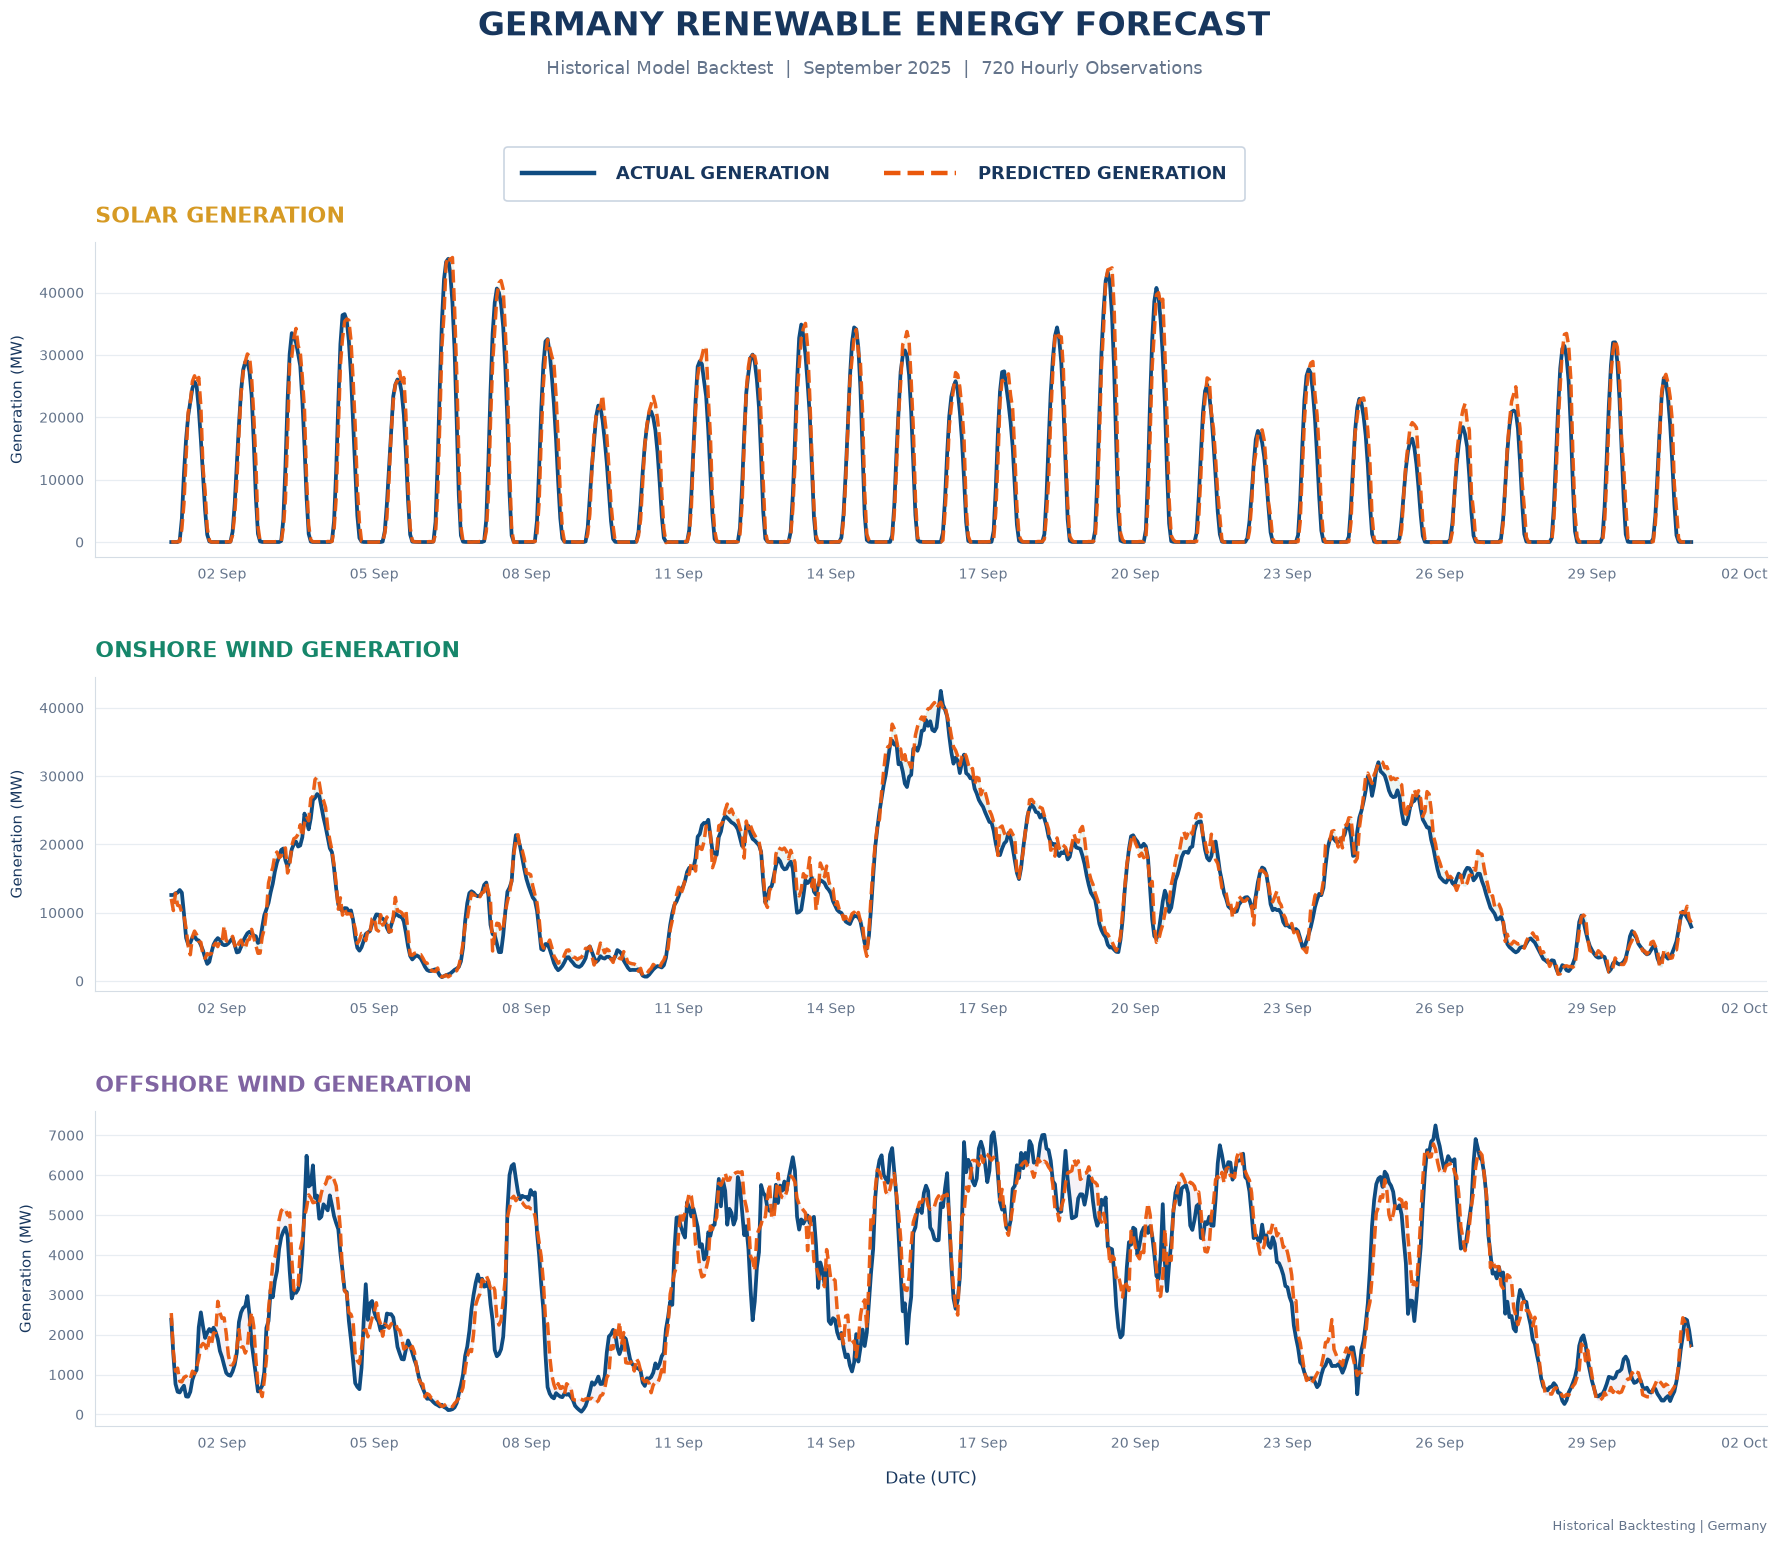

Plot saved: D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast\backtesting\plots\actual_vs_predicted_september_2025.png
File exists: True


In [34]:
# ============================================================
# GERMANY RENEWABLE ENERGY FORECAST — SEPTEMBER 2025
# PROFESSIONAL HISTORICAL BACKTEST VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. COLOUR PALETTE
# ------------------------------------------------------------

ACTUAL_COLOR = "#0F4C81"       # Deep navy blue
PREDICTED_COLOR = "#EA580C"    # Warm orange

NAVY = "#17365D"
SOLAR_COLOR = "#D69A24"
ONSHORE_COLOR = "#16866A"
OFFSHORE_COLOR = "#8064A2"

GREY = "#64748B"
GRID = "#E8EDF2"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D5DDE5",
    "axes.labelcolor": NAVY,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "font.family": "DejaVu Sans",
    "font.size": 11
})

# ------------------------------------------------------------
# 2. CREATE FIGURE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 1,
    figsize=(19, 16),
    sharex=True
)

fig.subplots_adjust(
    top=0.83,
    bottom=0.09,
    left=0.09,
    right=0.97,
    hspace=0.38
)

technologies = [
    ("solar", "SOLAR GENERATION", SOLAR_COLOR),
    ("onshore", "ONSHORE WIND GENERATION", ONSHORE_COLOR),
    ("offshore", "OFFSHORE WIND GENERATION", OFFSHORE_COLOR)
]

# ------------------------------------------------------------
# 3. PLOT ACTUAL AND PREDICTED GENERATION
# ------------------------------------------------------------

for ax, (technology, title, accent) in zip(axes, technologies):

    time = backtest_results["time"]

    actual = backtest_results[
        f"{technology}_actual_mw"
    ]

    predicted = backtest_results[
        f"{technology}_predicted_mw"
    ]

    # Actual generation — solid navy blue
    ax.plot(
        time,
        actual,
        color=ACTUAL_COLOR,
        linewidth=2.7,
        linestyle="-",
        zorder=3
    )

    # Predicted generation — dashed orange
    ax.plot(
        time,
        predicted,
        color=PREDICTED_COLOR,
        linewidth=2.5,
        linestyle="--",
        alpha=0.95,
        zorder=4
    )

    # Subtle difference shading
    ax.fill_between(
        time,
        actual,
        predicted,
        color=accent,
        alpha=0.08,
        zorder=1
    )

    # Technology heading
    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        color=accent,
        loc="left",
        pad=14
    )

    ax.set_ylabel(
        "Generation (MW)",
        fontsize=11,
        labelpad=10
    )

    # Grid styling
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=0.9
    )

    ax.grid(
        axis="x",
        visible=False
    )

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D5DDE5")
    ax.spines["bottom"].set_color("#D5DDE5")

    ax.tick_params(
        axis="both",
        labelsize=10,
        length=0,
        pad=8
    )

    # Show date labels on ALL three panels
    ax.tick_params(
        axis="x",
        labelbottom=True
    )

    ax.xaxis.set_major_locator(
        mdates.DayLocator(interval=3)
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d %b")
    )

# ------------------------------------------------------------
# 4. MAIN TITLE AND SUBTITLE
# ------------------------------------------------------------

fig.suptitle(
    "GERMANY RENEWABLE ENERGY FORECAST",
    fontsize=24,
    fontweight="bold",
    color=NAVY,
    y=0.975
)

fig.text(
    0.5,
    0.935,
    "Historical Model Backtest  |  September 2025  |  720 Hourly Observations",
    ha="center",
    fontsize=13,
    color=GREY
)

# ------------------------------------------------------------
# 5. EXPLICIT SHARED LEGEND WITH VISIBLE LABELS
# ------------------------------------------------------------

legend_handles = [

    Line2D(
        [0], [0],
        color=ACTUAL_COLOR,
        linewidth=3.2,
        linestyle="-",
        label="ACTUAL GENERATION"
    ),

    Line2D(
        [0], [0],
        color=PREDICTED_COLOR,
        linewidth=3.2,
        linestyle="--",
        label="PREDICTED GENERATION"
    )
]

shared_legend = fig.legend(
    handles=legend_handles,
    labels=[
        "ACTUAL GENERATION",
        "PREDICTED GENERATION"
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.895),
    ncol=2,
    fontsize=13,
    frameon=True,
    facecolor="white",
    edgecolor="#CBD5E1",
    framealpha=1,
    handlelength=4,
    handletextpad=1.2,
    columnspacing=3,
    borderpad=1
)

# Make legend text explicitly visible
for text_item in shared_legend.get_texts():
    text_item.set_color(NAVY)
    text_item.set_fontweight("bold")

shared_legend.get_frame().set_linewidth(1.2)

# ------------------------------------------------------------
# 6. AXIS LABEL AND FOOTER
# ------------------------------------------------------------

axes[-1].set_xlabel(
    "Date (UTC)",
    fontsize=12,
    color=NAVY,
    labelpad=14
)

fig.text(
    0.97,
    0.025,
    "Historical Backtesting | Germany",
    ha="right",
    fontsize=9,
    color=GREY
)

# ------------------------------------------------------------
# 7. DISPLAY
# ------------------------------------------------------------

# Save high-resolution plot
actual_predicted_plot = (
    root / "backtesting" / "plots" /
    "actual_vs_predicted_september_2025.png"
)

plt.savefig(
    actual_predicted_plot,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Plot saved:", actual_predicted_plot)
print("File exists:", actual_predicted_plot.exists())

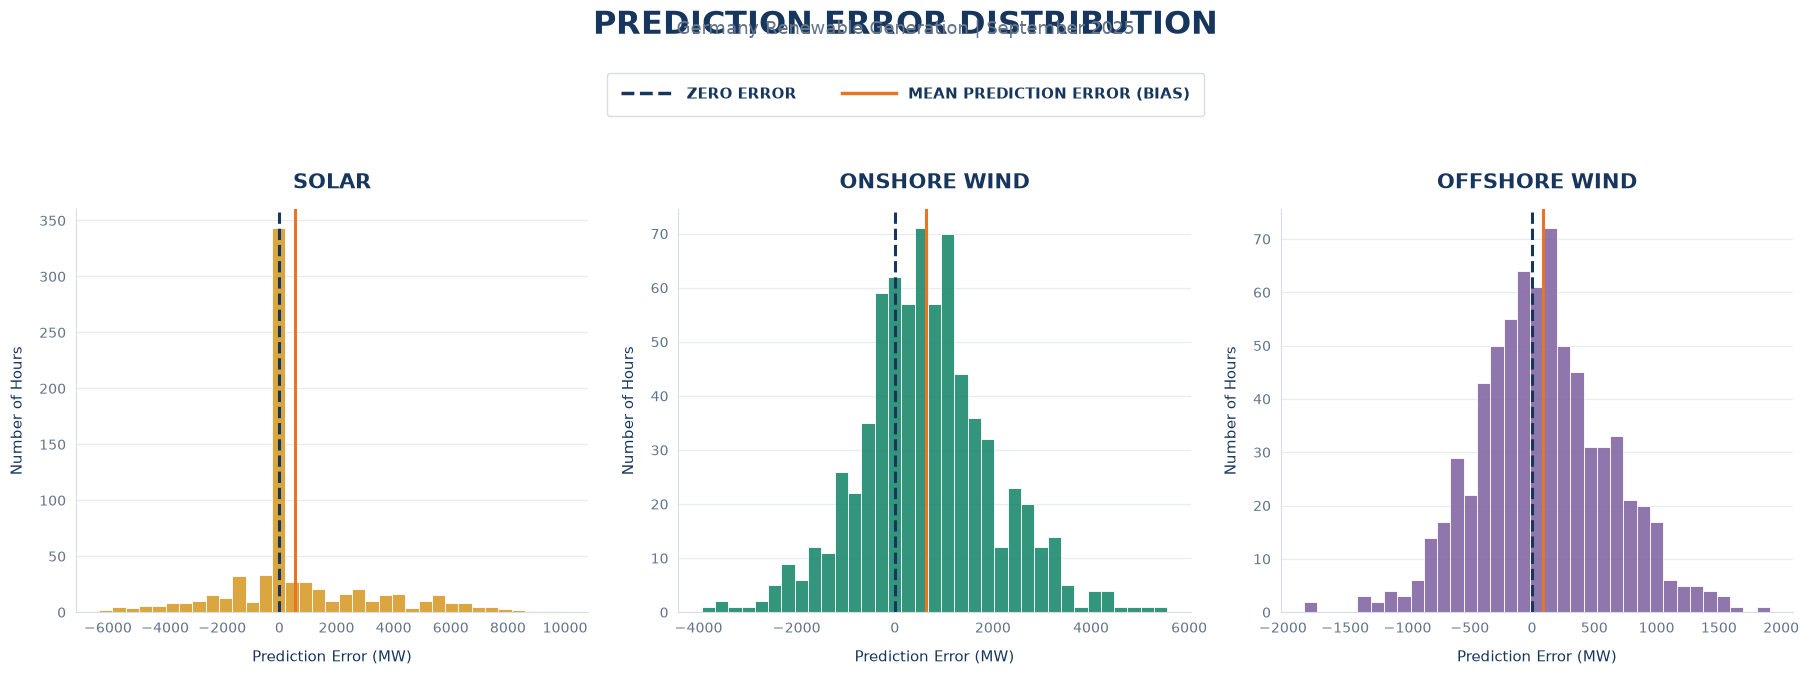

Plot saved: D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast\backtesting\plots\error_distribution_september_2025.png
File exists: True


In [35]:
# ============================================================
# PREDICTION ERROR DISTRIBUTION — SEPTEMBER 2025
# PROFESSIONAL VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Colours
NAVY = "#17365D"
GREY = "#64748B"
GRID = "#E8EDF2"

COLORS = {
    "solar": "#D69A24",
    "onshore": "#16866A",
    "offshore": "#8064A2"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 7)
)

fig.patch.set_facecolor("white")

technologies = [
    ("solar", "SOLAR"),
    ("onshore", "ONSHORE WIND"),
    ("offshore", "OFFSHORE WIND")
]

# ============================================================
# HISTOGRAMS
# ============================================================

for ax, (technology, title) in zip(axes, technologies):

    errors = backtest_results[
        f"{technology}_error_mw"
    ]

    accent = COLORS[technology]

    # Error distribution
    ax.hist(
        errors,
        bins=35,
        color=accent,
        edgecolor="white",
        linewidth=0.7,
        alpha=0.88
    )

    # Zero error reference
    ax.axvline(
        0,
        color=NAVY,
        linewidth=2.2,
        linestyle="--"
    )

    # Mean error
    ax.axvline(
        errors.mean(),
        color="#E87524",
        linewidth=2.2,
        linestyle="-"
    )

    # Panel title
    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        color=NAVY,
        pad=15
    )

    ax.set_xlabel(
        "Prediction Error (MW)",
        fontsize=11,
        color=NAVY,
        labelpad=10
    )

    ax.set_ylabel(
        "Number of Hours",
        fontsize=11,
        color=NAVY,
        labelpad=10
    )

    # Grid
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=0.9
    )

    ax.set_axisbelow(True)

    # Clean borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#D5DDE5")
    ax.spines["bottom"].set_color("#D5DDE5")

    ax.tick_params(
        labelsize=10,
        colors=GREY,
        length=0,
        pad=7
    )

# ============================================================
# SHARED LEGEND — EXPLICIT VISIBLE LABELS
# ============================================================

legend_handles = [

    Line2D(
        [0], [0],
        color=NAVY,
        linewidth=2.5,
        linestyle="--"
    ),

    Line2D(
        [0], [0],
        color="#E87524",
        linewidth=2.5,
        linestyle="-"
    )
]

shared_legend = fig.legend(
    handles=legend_handles,
    labels=[
        "ZERO ERROR",
        "MEAN PREDICTION ERROR (BIAS)"
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    fontsize=11,
    frameon=True,
    facecolor="white",
    edgecolor="#CBD5E1",
    handlelength=3.5,
    columnspacing=3,
    borderpad=0.9
)

# Force legend text to be visible
for item in shared_legend.get_texts():
    item.set_color(NAVY)
    item.set_fontweight("bold")

# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "PREDICTION ERROR DISTRIBUTION",
    fontsize=23,
    fontweight="bold",
    color=NAVY,
    y=0.99
)

fig.text(
    0.5,
    0.955,
    "Germany Renewable Generation | September 2025",
    ha="center",
    fontsize=13,
    color=GREY
)

plt.tight_layout(
    rect=[0.02, 0.03, 0.98, 0.85]
)

# Save high-resolution error distribution plot
error_plot = (
    root / "backtesting" / "plots" /
    "error_distribution_september_2025.png"
)

plt.savefig(
    error_plot,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Plot saved:", error_plot)
print("File exists:", error_plot.exists())

In [28]:
print("MONTHLY BACKTEST RESULTS")
print("=" * 60)

print("Columns:")
print(monthly_backtest.columns.tolist())

print("\nFirst five records:")
display(monthly_backtest.head())

print("\nNumber of evaluated months:", len(monthly_backtest))

MONTHLY BACKTEST RESULTS
Columns:
['month', 'hours', 'solar_MAE_MW', 'solar_WAPE_pct', 'onshore_MAE_MW', 'onshore_WAPE_pct', 'offshore_MAE_MW', 'offshore_WAPE_pct', 'average_WAPE_pct']

First five records:


,month,hours,solar_MAE_MW,solar_WAPE_pct,onshore_MAE_MW,onshore_WAPE_pct,offshore_MAE_MW,offshore_WAPE_pct,average_WAPE_pct
0,2025-09,720,1483.683189,16.598329,1158.434614,8.588131,416.454345,12.462991,12.549817
1,2026-02,672,747.096925,19.797922,1361.351032,8.200852,590.020138,10.744945,12.914573
2,2025-10,744,892.470201,18.228630,1437.242028,7.806105,537.066649,13.762537,13.265757
3,2025-03,744,932.582694,10.046483,1002.312026,11.472330,468.160582,18.427355,13.315389
4,2026-03,744,1606.659861,16.370887,1065.213132,8.710142,472.422937,15.188676,13.423235



Number of evaluated months: 30


In [31]:
# ============================================================
# EXPORT COMPLETE MONTHLY BACKTEST RESULTS
# ============================================================

# Create results folder if it doesn't exist
results_folder = root / "backtesting" / "results"
results_folder.mkdir(parents=True, exist_ok=True)

# Sort results chronologically
monthly_results_export = (
    monthly_backtest.copy()
    .sort_values("month")
    .reset_index(drop=True)
)

# Export CSV
monthly_csv_path = (
    results_folder / "monthly_backtest_metrics.csv"
)

monthly_results_export.to_csv(
    monthly_csv_path,
    index=False
)

# Verify export
print("=" * 60)
print("MONTHLY BACKTEST RESULTS — EXPORT COMPLETE")
print("=" * 60)

print("File:", monthly_csv_path)
print("Months exported:", len(monthly_results_export))
print("Columns:", len(monthly_results_export.columns))
print("File exists:", monthly_csv_path.exists())

display(monthly_results_export.head())

MONTHLY BACKTEST RESULTS — EXPORT COMPLETE
File: D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast\backtesting\results\monthly_backtest_metrics.csv
Months exported: 30
Columns: 9
File exists: True


,month,hours,solar_MAE_MW,solar_WAPE_pct,onshore_MAE_MW,onshore_WAPE_pct,offshore_MAE_MW,offshore_WAPE_pct,average_WAPE_pct
0,2024-04,720,1324.963717,14.400932,1428.754622,10.619533,607.567845,20.008658,15.009708
1,2024-05,744,1539.860542,13.315815,1123.248249,13.403723,496.087048,24.126559,16.948699
2,2024-06,720,1543.465766,12.577439,1103.368570,14.020239,523.562762,24.337779,16.978486
3,2024-07,744,1586.212778,12.680407,1031.133328,13.878356,498.633377,22.687931,16.415564
4,2024-08,744,1563.662409,13.011455,928.371146,13.268656,404.742406,21.060791,15.780301


In [32]:
# ============================================================
# EXPORT SEPTEMBER 2025 BACKTEST RESULTS
# ============================================================

september_file = (
    results_folder / "backtest_september_2025.csv"
)

backtest_results.to_csv(
    september_file,
    index=False
)

print("=" * 60)
print("SEPTEMBER 2025 BACKTEST — EXPORT COMPLETE")
print("=" * 60)

print("File:", september_file)
print("Hourly records:", len(backtest_results))
print("Columns:", len(backtest_results.columns))
print("File exists:", september_file.exists())

display(backtest_results.head())

SEPTEMBER 2025 BACKTEST — EXPORT COMPLETE
File: D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast\backtesting\results\backtest_september_2025.csv
Hourly records: 720
Columns: 10
File exists: True


,time,solar_actual_mw,solar_predicted_mw,onshore_actual_mw,onshore_predicted_mw,offshore_actual_mw,offshore_predicted_mw,solar_error_mw,onshore_error_mw,offshore_error_mw
0,2025-09-01 00:00:00+00:00,8.50,39.634616,12593.54,12022.112064,2375.40,2541.933105,31.134616,-571.427936,166.533105
1,2025-09-01 01:00:00+00:00,7.91,41.049436,12599.03,10317.754416,1490.00,1566.792294,33.139436,-2281.275584,76.792294
2,2025-09-01 02:00:00+00:00,7.47,4.851584,12846.25,12850.861482,765.38,1085.787628,-2.618416,4.611482,320.407628
3,2025-09-01 03:00:00+00:00,8.93,70.419619,12945.15,11072.845937,569.39,1160.690007,61.489619,-1872.304063,591.300007
4,2025-09-01 04:00:00+00:00,277.39,84.274922,13325.47,11000.047408,551.22,831.528706,-193.115078,-2325.422592,280.308706


In [33]:
# ============================================================
# EXPORT SEPTEMBER 2025 SUMMARY METRICS
# ============================================================

metrics_file = (
    results_folder / "september_2025_metrics.csv"
)

final_metrics.to_csv(
    metrics_file,
    index=False
)

print("=" * 60)
print("SEPTEMBER 2025 METRICS — EXPORT COMPLETE")
print("=" * 60)

print("File:", metrics_file)
print("Technologies:", len(final_metrics))
print("File exists:", metrics_file.exists())

display(final_metrics)

SEPTEMBER 2025 METRICS — EXPORT COMPLETE
File: D:\day-ahead-forecast\Germany-Renewable-Generation-Forecast\backtesting\results\september_2025_metrics.csv
Technologies: 3
File exists: True


,technology,MAE_MW,RMSE_MW,Bias_MW,WAPE_percent
0,solar,1483.683189,2517.250859,554.518375,16.598329
1,onshore,1158.434614,1504.674475,645.256151,8.588131
2,offshore,416.454345,536.487561,85.301368,12.462991
